# DBAC on mixed states, and a Bloch-sphere picture of the recursion

Everywhere else in this repository, DB-QITE is run on a *pure* initial state. Here we
check robustness to noise by passing the initial state through a single-qubit
depolarizing channel before cooling it,

$$
\rho_{\text{mixed}} = (1-p)\,\rho + p\,\frac{I}{2}, \qquad p \in [0, 1],
$$

and comparing the resulting fidelity-fidelity curve to the noiseless case. We then
visualize the DB-QITE recursion itself on the Bloch sphere for three representative
initial fidelities, to build intuition for *why* more recursion steps $k$ (equivalently,
more quantum instructions) are needed to reach a fixed target fidelity the further the
initial state starts from the ground state.

The sweeps live in [`scripts/dbac_mixed.py`](../scripts/dbac_mixed.py); the fidelity plot
uses `visualization.dbac_plots.plot_fidelity_fidelity` and the Bloch-sphere trajectories
use `visualization.bloch_sphere.plot_bloch_trajectory`.

In [1]:
%matplotlib inline
import sys
sys.path.append('..')

import numpy as np

from visualization import use_paper_style
from scripts.dbac_mixed import compare_pure_vs_mixed, bloch_trajectory_states, TARGET_FIDELITY
from functions.utils import rx_sweep

use_paper_style(font_size=16, figsize=(5, 3.5))
optimal_s_Mk = np.load("optimal_s_Mk.npy")

[Qibo 0.3.5|INFO|2026-10-12 12:55:39]: Using numpy backend on /CPU:0


## Pure vs. depolarized input, Circuit A ($M=1$, $k=1$)

/home/kay-otic/Code/dbac/.venv/lib/python3.13/site-packages/matplotlib/cbook.py:1811: ComplexWarning: Casting complex values to real discards the imaginary part
  return math.isfinite(val)
/home/kay-otic/Code/dbac/.venv/lib/python3.13/site-packages/matplotlib/cbook.py:1408: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asanyarray(x, float)
/home/kay-otic/Code/dbac/.venv/lib/python3.13/site-packages/matplotlib/text.py:1698: ComplexWarning: Casting complex values to real discards the imaginary part
  y = float(self.convert_yunits(y))
/home/kay-otic/Code/dbac/.venv/lib/python3.13/site-packages/matplotlib/text.py:1013: ComplexWarning: Casting complex values to real discards the imaginary part
  y = float(self.convert_yunits(self._y))
/home/kay-otic/Code/dbac/.venv/lib/python3.13/site-packages/matplotlib/text.py:864: ComplexWarning: Casting complex values to real discards the imaginary part
  posy = float(self.convert_yunits(y))


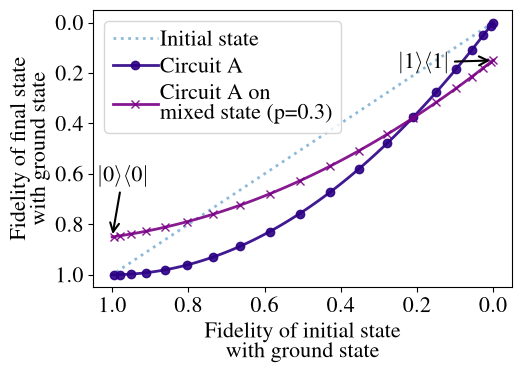

In [2]:
from visualization import plot_fidelity_fidelity

fidelities_initial, results = compare_pure_vs_mixed(optimal_s_Mk, M=1, k=1, depolarizing_p=0.3)
plot_fidelity_fidelity(fidelities_initial, fidelities_initial, results);

The depolarizing noise shifts the whole curve towards worse final fidelity, but
DBAC still cools the state -- the final-state curve stays below the diagonal "do nothing"
line.

## Bloch-sphere picture of the recursion

We pick three initial states with high, medium, and low fidelity with $|0\rangle$, run
DB-QITE, and plot every intermediate state as a latitude circle on the Bloch sphere. The
dashed black circle marks the target fidelity $F_{\text{target}}=0.9$.

In [3]:
thetas = np.linspace(0, 1, 100)
psis = rx_sweep(thetas, start=np.array([[0], [1]], dtype=complex))
texts = ["Initial state", r"$k=1$", r"$k=2$"]

### (a) High initial fidelity ($F_{\text{initial}}\approx 80\%$): reached with a
single $k=1$, $M=1$ step (one extra copy of the initial state).

/home/kay-otic/Code/dbac/.venv/lib/python3.13/site-packages/mpl_toolkits/mplot3d/axes3d.py:3603: ComplexWarning: Casting complex values to real discards the imaginary part
  UVW = np.column_stack(input_args[3:]).astype(float)
/home/kay-otic/Code/dbac/.venv/lib/python3.13/site-packages/matplotlib/cbook.py:1408: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asanyarray(x, float)
/home/kay-otic/Code/dbac/.venv/lib/python3.13/site-packages/matplotlib/axis.py:845: ComplexWarning: Casting complex values to real discards the imaginary part
  data = np.asanyarray(data, dtype=float)


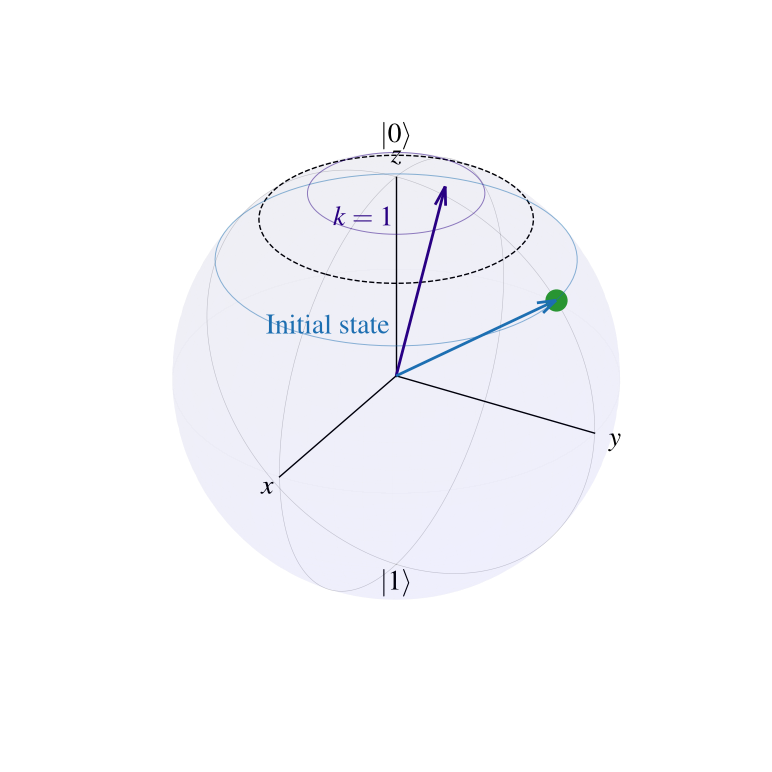

In [4]:
from visualization import plot_bloch_trajectory

states_good = bloch_trajectory_states(optimal_s_Mk, psis, 70, M=1, k=1)
plot_bloch_trajectory(states_good, texts[:len(states_good)], marker='o', marker_color='C2',
                       target_fidelity=TARGET_FIDELITY);

### (b) Medium initial fidelity ($F_{\text{initial}}\approx 60\%$): needs $k=2$
steps at $M=1$ (three extra copies in total).

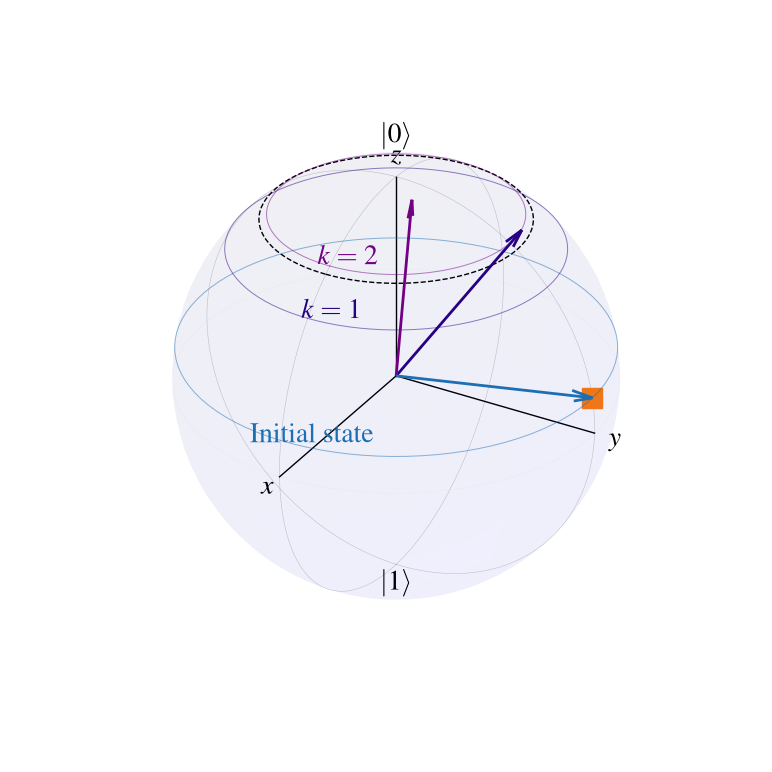

In [5]:
states_mid = bloch_trajectory_states(optimal_s_Mk, psis, 55, M=1, k=2)
plot_bloch_trajectory(states_mid, texts[:len(states_mid)], marker='s', marker_color='C1',
                       target_fidelity=TARGET_FIDELITY);

### (c) Low initial fidelity ($F_{\text{initial}}\approx 10\%$): even $k=2$ steps
at $M=2$ fall short of the target -- illustrating that cooling performance is fundamentally
bounded by how many quantum instructions are available.

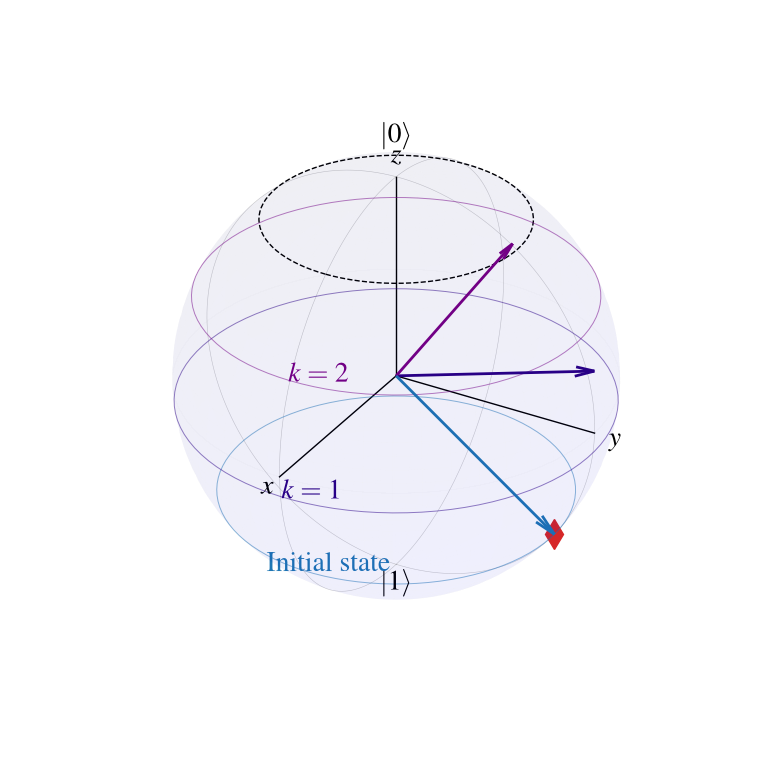

In [6]:
states_bad = bloch_trajectory_states(optimal_s_Mk, psis, 30, M=2, k=2)
plot_bloch_trajectory(states_bad, texts[:len(states_bad)], marker='d', marker_color='C3',
                       target_fidelity=TARGET_FIDELITY);

---
To regenerate all the figures in `plots/` from the command line instead of this notebook, run:

```bash
python scripts/dbac_mixed.py
```